In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
data_dir = "/content/drive/MyDrive/datas"

import os
print("dataset:")
print(os.listdir(data_dir))

dataset:
['enh_1436_mask.png', 'enh_1443.png', 'enh_1435_mask.png', 'enh_1424.png', 'enh_1419_mask.png', 'enh_1414.png', 'enh_1423.png', 'enh_1416_mask.png', 'enh_1446_mask.png', 'enh_1418_mask.png', 'enh_1438.png', 'enh_1430_mask.png', 'enh_1439_mask.png', 'enh_1442.png', 'enh_1432_mask.png', 'enh_1442_mask.png', 'enh_1441.png', 'enh_1434.png', 'enh_1429.png', 'enh_1446.png', 'enh_1433.png', 'enh_1415_mask.png', 'enh_1422.png', 'enh_1416.png', 'enh_1413_mask.png', 'enh_1439.png', 'enh_1426.png', 'enh_1412.png', 'enh_1419.png', 'enh_1418.png', 'enh_1410_mask.png', 'enh_1420_mask.png', 'enh_1440_mask.png', 'enh_1436.png', 'enh_1467.png', 'enh_1451_mask.png', 'enh_1458_mask.png', 'enh_1482.png', 'enh_1483_mask.png', 'enh_1456_mask.png', 'enh_1478.png', 'enh_1473_mask.png', 'enh_1485_mask.png', 'enh_1479_mask.png', 'enh_1453_mask.png', 'enh_1477_mask.png', 'enh_1465_mask.png', 'enh_1464.png', 'enh_1448.png', 'enh_1483.png', 'enh_1476.png', 'enh_1454_mask.png', 'enh_1458.png', 'enh_1466.pn

In [3]:
import os
from glob import glob

import numpy as np
from PIL import Image

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms as T

In [ ]:
import random
import torch

class BrainMRIDataset(Dataset):
    def __init__(self, root_dir, image_size=(256, 256), augment=False):
        self.root_dir = root_dir
        self.image_size = image_size
        self.augment = augment

        mask_paths = sorted(glob(os.path.join(root_dir, "*_mask.png")))
        self.pairs = []

        for m_path in mask_paths:
            img_path = m_path.replace("_mask", "")
            if os.path.exists(img_path):
                self.pairs.append((img_path, m_path))

        if len(self.pairs) == 0:
            raise ValueError("Hiç eşleşen image-mask bulunamadı.")

        self.img_transform = T.Compose([
            T.Resize(image_size),
            T.ToTensor(),
            T.Normalize(mean=[0.5], std=[0.5])
        ])

        self.mask_transform = T.Compose([
            T.Resize(image_size, interpolation=Image.NEAREST),
            T.ToTensor(),
        ])

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]

        img = Image.open(img_path).convert("L")
        mask = Image.open(mask_path).convert("L")

        img = self.img_transform(img)
        mask = self.mask_transform(mask)
        mask = (mask > 0.5).float()

        if self.augment:
            if random.random() < 0.5:
                img = torch.flip(img, dims=[2])
                mask = torch.flip(mask, dims=[2])

            if random.random() < 0.5:
                img = torch.flip(img, dims=[1])
                mask = torch.flip(mask, dims=[1])

            k = random.randint(0, 3)
            if k > 0:
                img = torch.rot90(img, k, dims=[1, 2])
                mask = torch.rot90(mask, k, dims=[1, 2])

        return img, mask


In [5]:
#UNet modeli
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class UNet(nn.Module):
    def __init__(self, in_channels=1, out_channels=1, base_ch=32):
        super().__init__()

        self.enc1 = DoubleConv(in_channels, base_ch)
        self.enc2 = DoubleConv(base_ch, base_ch * 2)
        self.enc3 = DoubleConv(base_ch * 2, base_ch * 4)
        self.enc4 = DoubleConv(base_ch * 4, base_ch * 8)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = DoubleConv(base_ch * 8, base_ch * 16)

        self.up4 = nn.ConvTranspose2d(base_ch * 16, base_ch * 8, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(base_ch * 16, base_ch * 8)

        self.up3 = nn.ConvTranspose2d(base_ch * 8, base_ch * 4, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(base_ch * 8, base_ch * 4)

        self.up2 = nn.ConvTranspose2d(base_ch * 4, base_ch * 2, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(base_ch * 4, base_ch * 2)

        self.up1 = nn.ConvTranspose2d(base_ch * 2, base_ch, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(base_ch * 2, base_ch)

        self.out_conv = nn.Conv2d(base_ch, out_channels, kernel_size=1)

    def forward(self, x):
        c1 = self.enc1(x)
        p1 = self.pool(c1)

        c2 = self.enc2(p1)
        p2 = self.pool(c2)

        c3 = self.enc3(p2)
        p3 = self.pool(c3)

        c4 = self.enc4(p3)
        p4 = self.pool(c4)

        bn = self.bottleneck(p4)

        u4 = self.up4(bn)
        u4 = torch.cat([u4, c4], dim=1)
        c5 = self.dec4(u4)

        u3 = self.up3(c5)
        u3 = torch.cat([u3, c3], dim=1)
        c6 = self.dec3(u3)

        u2 = self.up2(c6)
        u2 = torch.cat([u2, c2], dim=1)
        c7 = self.dec2(u2)

        u1 = self.up1(c7)
        u1 = torch.cat([u1, c1], dim=1)
        c8 = self.dec1(u1)

        out = self.out_conv(c8)
        out = torch.sigmoid(out)  # [0,1]
        return out


In [ ]:


def dice_coef(pred, target, eps=1e-7):
    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    intersection = (pred * target).sum(dim=1)
    union = pred.sum(dim=1) + target.sum(dim=1)

    dice = (2 * intersection + eps) / (union + eps)
    return dice.mean()


def iou_coef(pred, target, eps=1e-7):
    pred = pred.view(pred.size(0), -1)
    target = target.view(target.size(0), -1)

    intersection = (pred * target).sum(dim=1)
    union = pred.sum(dim=1) + target.sum(dim=1) - intersection

    iou = (intersection + eps) / (union + eps)
    return iou.mean()


class DiceBCELoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCELoss()

    def forward(self, pred, target):
        bce = self.bce(pred, target)
        dice = 1 - dice_coef(pred, target)
        return bce + dice


In [ ]:
from torch.utils.data import DataLoader, Subset
import torch

data_dir = "/content/drive/MyDrive/datas"

base_dataset = BrainMRIDataset(root_dir=data_dir, image_size=(256, 256), augment=False)
N = len(base_dataset)
print("Toplam örnek:", N)

train_ratio = 0.7
val_ratio   = 0.15
test_ratio  = 0.15

train_size = int(N * train_ratio)
val_size   = int(N * val_ratio)
test_size  = N - train_size - val_size

indices = torch.randperm(N)
train_idx = indices[:train_size]
val_idx   = indices[train_size:train_size+val_size]
test_idx  = indices[train_size+val_size:]

train_base = BrainMRIDataset(root_dir=data_dir, image_size=(256, 256), augment=True)
eval_base  = BrainMRIDataset(root_dir=data_dir, image_size=(256, 256), augment=False)

train_ds = Subset(train_base, train_idx)
val_ds   = Subset(eval_base,  val_idx)
test_ds  = Subset(eval_base,  test_idx)

print(f"Train: {len(train_ds)}, Val: {len(val_ds)}, Test: {len(test_ds)}")

batch_size = 4
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=0)


Toplam örnek: 2192
Train: 1534, Val: 328, Test: 330


In [ ]:
# Eğitim ve değerlendirme fonksiyonları

def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    running_dice = 0.0

    for imgs, masks in loader:
        imgs = imgs.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imgs.size(0)
        running_dice += dice_coef(outputs.detach(), masks).item() * imgs.size(0)

    epoch_loss = running_loss / len(loader.dataset)
    epoch_dice = running_dice / len(loader.dataset)
    return epoch_loss, epoch_dice


@torch.no_grad()
def eval_model(model, loader, device):
    model.eval()
    running_dice = 0.0
    running_iou = 0.0

    for imgs, masks in loader:
        imgs = imgs.to(device)
        masks = masks.to(device)

        outputs = model(imgs)
        running_dice += dice_coef(outputs, masks).item() * imgs.size(0)
        running_iou += iou_coef(outputs, masks).item() * imgs.size(0)

    dice = running_dice / len(loader.dataset)
    iou = running_iou / len(loader.dataset)
    return dice, iou


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Kullanılan cihaz:", device)

model = UNet(in_channels=1, out_channels=1, base_ch=64).to(device)
criterion = DiceBCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)


scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",     
    factor=0.5,      
    patience=5      
)

num_epochs = 150
best_val_dice = 0.0

for epoch in range(1, num_epochs + 1):
    train_loss, train_dice = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_dice, val_iou = eval_model(model, val_loader, device)

    print(f"Epoch [{epoch}/{num_epochs}] "
          f"Train Loss: {train_loss:.4f}  Train Dice: {train_dice:.4f}  "
          f"Val Dice: {val_dice:.4f}  Val IoU: {val_iou:.4f}")

 
    scheduler.step(val_dice)

    if val_dice > best_val_dice:
        best_val_dice = val_dice
        save_path = "/content/model.pth"
        torch.save(model.state_dict(), save_path)
        print(f"   En iyi model kaydedildi: {save_path}")

print("Eğitim bitti. En iyi Val Dice:", best_val_dice)


Kullanılan cihaz: cuda
Epoch [1/150] Train Loss: 0.9893  Train Dice: 0.1379  Val Dice: 0.2857  Val IoU: 0.1992
   En iyi model kaydedildi: /content/model.pth
Epoch [2/150] Train Loss: 0.7534  Train Dice: 0.3256  Val Dice: 0.2683  Val IoU: 0.1845
Epoch [3/150] Train Loss: 0.6899  Train Dice: 0.3859  Val Dice: 0.4449  Val IoU: 0.3267
   En iyi model kaydedildi: /content/model.pth
Epoch [4/150] Train Loss: 0.6340  Train Dice: 0.4347  Val Dice: 0.3713  Val IoU: 0.2714
Epoch [5/150] Train Loss: 0.5943  Train Dice: 0.4704  Val Dice: 0.4560  Val IoU: 0.3259
   En iyi model kaydedildi: /content/model.pth
Epoch [6/150] Train Loss: 0.5815  Train Dice: 0.4814  Val Dice: 0.5371  Val IoU: 0.4125
   En iyi model kaydedildi: /content/model.pth
Epoch [7/150] Train Loss: 0.5589  Train Dice: 0.5022  Val Dice: 0.5444  Val IoU: 0.4218
   En iyi model kaydedildi: /content/model.pth
Epoch [8/150] Train Loss: 0.5397  Train Dice: 0.5195  Val Dice: 0.4437  Val IoU: 0.3180
Epoch [9/150] Train Loss: 0.5273  Trai

In [ ]:
import torch
import numpy as np

@torch.no_grad()
def evaluate_on_loader(model, loader, device):
    model.eval()
    total_dice = 0.0
    total_iou  = 0.0
    total_sens = 0.0
    total_spec = 0.0
    total_samples = 0

    for imgs, masks in loader:
        imgs  = imgs.to(device)
        masks = masks.to(device)

        preds = model(imgs)

        
        total_dice += dice_coef(preds, masks).item() * imgs.size(0)
        total_iou  += iou_coef(preds, masks).item() * imgs.size(0)

        
        preds_bin = (preds > 0.5).float()

       
        p = preds_bin.view(-1)
        t = masks.view(-1)

        TP = (p * t).sum()
        TN = ((1 - p) * (1 - t)).sum()
        FP = (p * (1 - t)).sum()
        FN = ((1 - p) * t).sum()

        sens = TP / (TP + FN + 1e-7)
        spec = TN / (TN + FP + 1e-7)

        total_sens += sens.item() * imgs.size(0)
        total_spec += spec.item() * imgs.size(0)
        total_samples += imgs.size(0)

    return (
        total_dice / total_samples,
        total_iou  / total_samples,
        total_sens / total_samples,
        total_spec / total_samples,
    )


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

best_model_path = "/content/model.pth"  
best_model = UNet(in_channels=1, out_channels=1, base_ch=64).to(device)
best_model.load_state_dict(torch.load(best_model_path, map_location=device))
best_model.eval()


test_dice, test_iou, test_sens, test_spec = evaluate_on_loader(best_model, test_loader, device)

print("===== TEST METRIKLERI =====")
print(f"Test Dice       : {test_dice:.4f}")
print(f"Test IoU        : {test_iou:.4f}")
print(f"Test Sensitivity: {test_sens:.4f}")
print(f"Test Specificity: {test_spec:.4f}")


===== TEST METRIKLERI =====
Test Dice       : 0.7491
Test IoU        : 0.6478
Test Sensitivity: 0.7876
Test Specificity: 0.9971


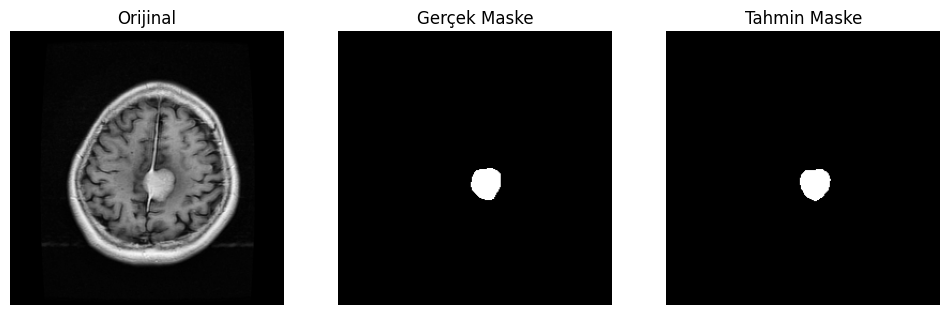

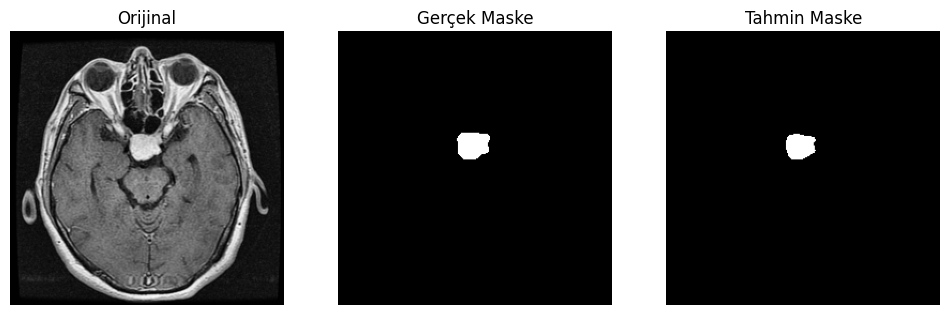

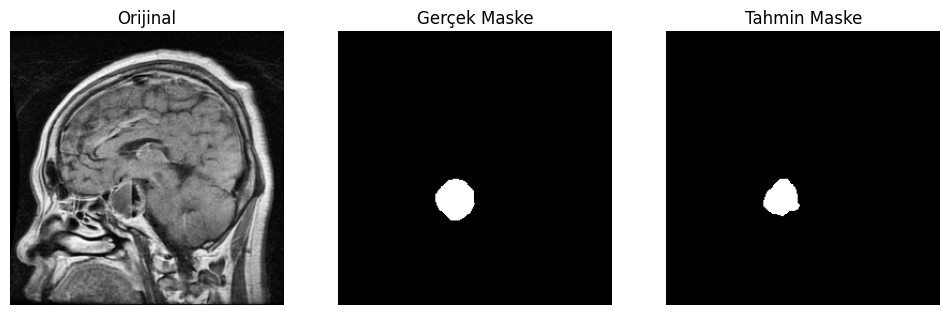

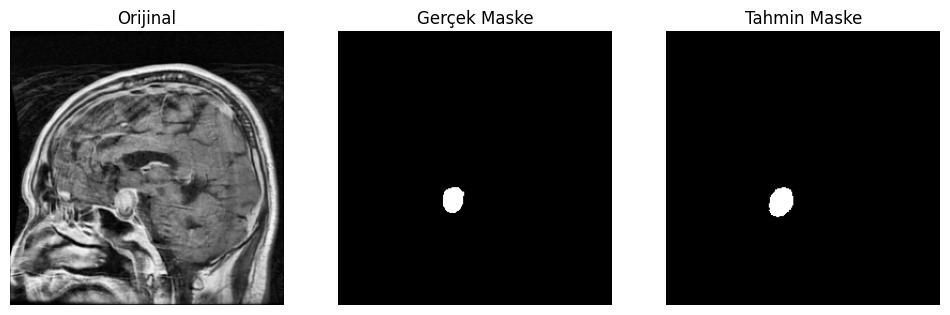

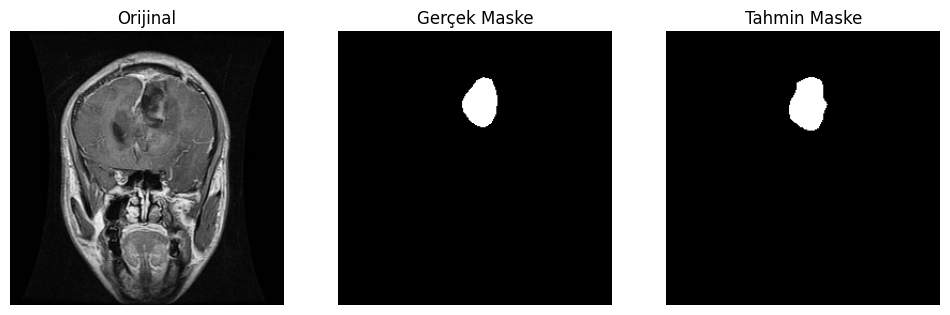

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch

best_model.eval()

n_show = 5
rand_idx = np.random.choice(len(test_ds), size=min(n_show, len(test_ds)), replace=False)

for i, idx in enumerate(rand_idx):
    img, mask = test_ds[idx]          
    img = img.unsqueeze(0).to(device) 
    mask = mask.unsqueeze(0).to(device)

    with torch.no_grad():
        pred = best_model(img)       

   
    img_np  = img[0,0].cpu().numpy()
    mask_np = mask[0,0].cpu().numpy()
    pred_np = pred[0,0].cpu().numpy()

    pred_bin = (pred_np > 0.5).astype(np.float32)

    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1); plt.imshow(img_np, cmap='gray');      plt.title("Orijinal");       plt.axis('off')
    plt.subplot(1,3,2); plt.imshow(mask_np, cmap='gray');     plt.title("Gerçek Maske");   plt.axis('off')
    plt.subplot(1,3,3); plt.imshow(pred_bin, cmap='gray');    plt.title("Tahmin Maske");   plt.axis('off')
    plt.show()
